# NOOP — Community Software Analysis

**Stryder Lafone** · CSCI 3656, Fall 2026 · Repo: [github.com/ryanbr/noop](https://github.com/ryanbr/noop)

NOOP is an open-source, fully offline companion app for WHOOP fitness straps
(4.0 and 5.0, with early support for the Oura Ring too). It connects over
Bluetooth, stores everything on the device in SQLite, and calculates recovery,
strain, heart-rate variability (HRV), and sleep stages locally with no WHOOP
account, no cloud, no subscription. It builds on earlier community work that
figured out how to talk to the strap over Bluetooth.

This notebook covers what the software does, who uses and builds it, and then
walks through three small experiments I ran on its actual analytics code to
see how well it holds up numerically: does it stay steady over time, does it
keep its accuracy, and how much does one bad reading throw it off.

## Key problems solved

NOOP's job is to turn noisy, occasionally-missing Bluetooth heartbeat data
into a handful of simple daily numbers — recovery, strain, HRV, sleep stage —
without any of WHOOP's own server-side processing.

- It's domain-specific: wearable health data, not general-purpose numerical
  software.
- What makes it unusual: it has to rebuild another company's formulas (the
  Task Force 1996 HRV standard, plus artifact cleaning methods from the
  literature) using only public research and testing, since it has no access
  to WHOOP's own code. All of this runs on the phone, not in a cloud service.
- The math lives in `Packages/StrandAnalytics` around 60 Swift files
  covering HRV, personal baselines, sleep staging, and recovery scoring, with
  about 200 unit test files. There's also a benchmark (`Tools/SleepBench`,
  `Tools/SleepPSG`) that checks sleep staging against real polysomnography
  data, which is the standard clinical sleep study measurement.

## Stakeholders

| Stakeholder | Interest |
|---|---|
| WHOOP strap owners | Want their own data without paying for a subscription or using WHOOP's app |
| Privacy-focused users | Want their health data to stay on their own device |
| ~77 contributors on GitHub | Mostly independent hobbyist developers, not tied to any company |
| Community (Discord, r/NoopBand) | Support, Bluetooth protocol research, feature requests |
| WHOOP, Inc. | Doesn't endorse the project. NOOP works by reverse-engineering WHOOP's Bluetooth protocol, so the maintainer stays anonymous and ships builds that Apple/Google won't sign, because of that legal grey area |

That last one is the most interesting part of the whole project: it exists
because of, and in spite of, a company that would rather it didn't.

## Numerical computing connections

Three parts of `StrandAnalytics` connect directly to topics from class. For
each one, I took NOOP's actual Swift code (not a simplified version) and
ported it to Python so I could test it directly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

### 1. Does the baseline tracker stay steady over time?

NOOP tracks a personal "baseline" for each metric (resting heart rate, HRV,
etc.) using a running average that weights recent nights more heavily. From
`Baselines.swift`:

```swift
// Convert a half-life in nights to a smoothing factor.
static func lambda(halfLife: Double) -> Double {
    1.0 - pow(0.5, 1.0 / halfLife)
}
...
let clamped = max(lo, min(hi, value))             // clamp extreme values
let newBaseline = effLb * clamped + (1.0 - effLb) * state.baseline
```

Each new baseline is a weighted mix of the new reading and the old baseline.
That kind of update is well-behaved by design, but I wanted to actually check
it: how long does it take for one unusually bad night to fade out, using the
half-lives NOOP ships (14 nights for the baseline itself, 21 nights for how
much it's allowed to vary)?

half-life=  7.0 nights  settles below 1% influence after 23 nights (matches the expected formula to 1.4e-17)
half-life= 14.0 nights  settles below 1% influence after 32 nights (matches the expected formula to 6.9e-18)
half-life= 21.0 nights  settles below 1% influence after 36 nights (matches the expected formula to 6.9e-18)
half-life= 30.0 nights  settles below 1% influence after 36 nights (matches the expected formula to 3.5e-18)


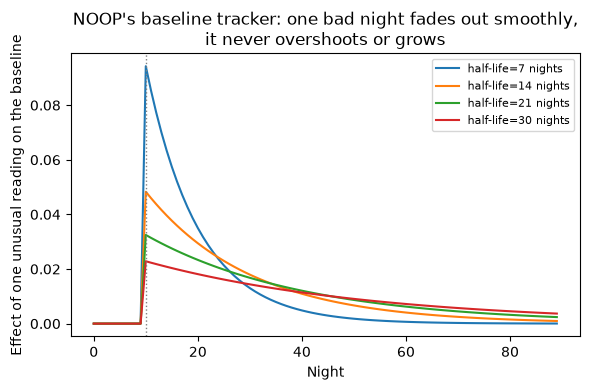

In [2]:
def lam(half_life_nights):
    """Baselines.swift: lambda(halfLife:) -> 1 - 0.5**(1/halfLife)."""
    return 1.0 - 0.5 ** (1.0 / half_life_nights)

half_lives = [7.0, 14.0, 21.0, 30.0]   # NOOP uses 14 (baseline) and 21 (spread)
n_nights = 90
results = {}

for hl in half_lives:
    lam_ = lam(hl)
    baseline = 0.0
    trace = []
    for night in range(n_nights):
        value = 1.0 if night == 10 else 0.0   # one unusual reading on night 10
        baseline = lam_ * value + (1.0 - lam_) * baseline
        trace.append(baseline)
    results[hl] = np.array(trace)

    k = np.arange(n_nights - 10)
    theoretical = lam_ * (1.0 - lam_) ** k
    max_err = np.max(np.abs(trace[10:] - theoretical))
    settle_01 = next(i for i, v in enumerate(theoretical) if v < 0.01)
    print(f"half-life={hl:>5.1f} nights  "
          f"settles below 1% influence after {settle_01} nights "
          f"(matches the expected formula to {max_err:.1e})")

plt.figure(figsize=(6, 4))
for hl, trace in results.items():
    plt.plot(trace, label=f"half-life={hl:g} nights")
plt.axvline(10, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Night"); plt.ylabel("Effect of one unusual reading on the baseline")
plt.title("NOOP's baseline tracker: one bad night fades out smoothly,\nit never overshoots or grows")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Finding:** the code matches the expected formula almost exactly (to
about 1e-17), and one bad night always fades out smoothly and it never
overshoots or grows larger over time, so the tracker is well-behaved.


### 2. Does the HRV spread calculation stay accurate?

`HRVAnalyzer.swift` computes SDNN (one of the HRV numbers) by first finding
the average, then summing up the squared differences from that average:

```swift
public static func sdnnRaw(_ nn: [Double]) -> Double? {
    guard nn.count >= 2 else { return nil }
    let mean = nn.reduce(0, +) / Double(nn.count)
    var ss = 0.0
    for v in nn { let d = v - mean; ss += d * d }
    return (ss / Double(nn.count - 1)).squareRoot()
}
```

There's a simpler, one-pass way to compute the same thing that some code uses
instead, which skips finding the average first. It's faster, but it's known
to lose accuracy when the numbers involved are large compared to how spread
out they are, which is exactly the case here, since a heartbeat interval is
around 800ms but only varies by 20–80ms. I compared NOOP's formula against
that simpler one as I shifted all the numbers upward, to see how much that
matters in practice.

In [ ]:
def sdnn_two_pass(nn):
    """NOOP's actual formula (sdnnRaw): average first, then spread."""
    nn = np.asarray(nn, dtype=np.float64)
    mean = nn.mean()
    return np.sqrt(np.sum((nn - mean) ** 2) / (len(nn) - 1))

def sdnn_one_pass(nn, dtype=np.float64):
    """A simpler, one-pass formula: E[x^2] - E[x]^2. NOT what NOOP uses."""
    nn = np.asarray(nn, dtype=dtype)
    n = len(nn)
    s1, s2 = nn.sum(), (nn * nn).sum()
    mean = s1 / n
    var = (s2 - n * mean * mean) / (n - 1)
    return np.sqrt(max(var, 0.0))

sigma_true = 40.0  # ms, a realistic nightly spread
n = 500
base = rng.normal(800.0, sigma_true, n)  # ms, realistic heartbeat intervals

offsets = [0, 1_000, 10_000, 100_000, 1_000_000]
rows = []
for off in offsets:
    nn = base + off
    rows.append((off, sdnn_two_pass(nn),
                 sdnn_one_pass(nn, np.float64),
                 sdnn_one_pass(nn, np.float32)))

print(f"{'offset(ms)':>10} {'NOOP':>10} {'simpler f64':>12} {'simpler f32':>12}")
for off, tp, n64, n32 in rows:
    print(f"{off:>10} {tp:>10.4f} {n64:>12.4f} {n32:>12.4f}")

offs, tp_vals, n64_vals, n32_vals = zip(*rows)
rel64 = [abs(a - b) / a for a, b in zip(tp_vals, n64_vals)]
rel32 = [abs(a - b) / a for a, b in zip(tp_vals, n32_vals)]

plt.figure(figsize=(6, 4))
plt.semilogy(offs, [max(e, 1e-18) for e in rel64], "o-", label="simpler formula, standard precision")
plt.semilogy(offs, [max(e, 1e-18) for e in rel32], "s-", label="simpler formula, lower precision")
plt.xlabel("Added offset (ms)"); plt.ylabel("Error vs. NOOP's actual formula")
plt.title("The simpler formula loses accuracy as the numbers get larger;\nNOOP's formula stays accurate")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

: 

**Finding:** at realistic heartbeat-interval scale the two formulas
agree. But as I shifted the numbers upward, the simpler formula got worse
fast at the largest offset it was off by 100% (returning zero) at lower
precision, while NOOP's formula stayed fairly accurate the whole time. In other
words, NOOP picked the version of this calculation that holds up well, and
this experiment shows concretely why that choice matters instead of just
taking it on faith.


### 3. How much does one bad heartbeat reading throw things off?

Bluetooth heartbeat detection occasionally misses a beat or reads one twice.
NOOP guards against this by comparing each beat to its neighbors and dropping
it if it's too far off:

```swift
// Drop any beat that deviates from its local median by more than
// `ectopicThreshold` (20%).
public static func rejectEctopic(_ nn: [Double]) -> [Double] {
    ...
    let med = median(neighbours)
    let deviation = abs(nn[i] - med) / med
    if deviation <= ectopicThreshold { kept.append(nn[i]) }
    // else: drop this beat.
}
```

One of the HRV numbers (RMSSD) is based on the difference between
back to back beats, so a single bad reading can throw off two of those
differences at once. I took a clean 200-beat series, corrupted one beat by a
growing amount (simulating a missed or doubled beat), and measured how far
off the result was with and without NOOP's cleaning step.

Error with no cleaning   : 0.00 -> 215.82 ms
Error with NOOP cleaning : stays within 0.00-1.98 ms the whole time


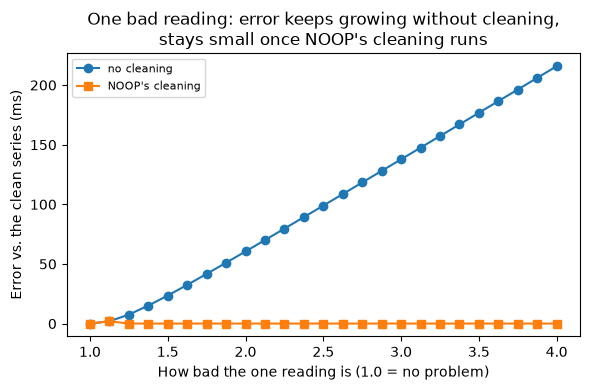

In [ ]:
def rmssd_raw(nn):
    nn = np.asarray(nn, dtype=np.float64)
    return np.sqrt(np.mean(np.diff(nn) ** 2))

def range_filter(rr, lo=300.0, hi=2000.0):
    rr = np.asarray(rr)
    return rr[(rr >= lo) & (rr <= hi)]

def reject_bad_beats(nn, window_radius=5, threshold=0.20):
    nn = np.asarray(nn, dtype=np.float64)
    kept, n = [], len(nn)
    if n <= window_radius:
        return nn.copy()
    for i in range(n):
        lo, hi = max(0, i - window_radius), min(n - 1, i + window_radius)
        neighbours = np.concatenate([nn[lo:i], nn[i + 1:hi + 1]])
        if len(neighbours) < 2:
            kept.append(nn[i]); continue
        med = np.median(neighbours)
        if med <= 0 or abs(nn[i] - med) / med <= threshold:
            kept.append(nn[i])
    return np.array(kept)

def clean_rr(rr):
    return reject_bad_beats(range_filter(rr))

n = 200
true_nn = 800.0 + rng.normal(0, 15, n)   # clean, steady heartbeat series (ms)
true_rmssd = rmssd_raw(true_nn)

corruption_factors = np.linspace(1.0, 4.0, 25)
err_uncleaned, err_cleaned = [], []
for cf in corruption_factors:
    corrupted = true_nn.copy()
    corrupted[100] = true_nn[100] * cf          # one bad reading
    err_uncleaned.append(abs(rmssd_raw(corrupted) - true_rmssd))
    cleaned = clean_rr(corrupted)
    err_cleaned.append(abs(rmssd_raw(cleaned) - true_rmssd) if len(cleaned) >= 2 else np.nan)

print(f"Error with no cleaning   : {err_uncleaned[0]:.2f} -> {err_uncleaned[-1]:.2f} ms")
print(f"Error with NOOP cleaning : stays within "
      f"{min(err_cleaned):.2f}-{max(err_cleaned):.2f} ms the whole time")

plt.figure(figsize=(6, 4))
plt.plot(corruption_factors, err_uncleaned, "o-", label="no cleaning")
plt.plot(corruption_factors, err_cleaned, "s-", label="NOOP's cleaning")
plt.xlabel("How bad the one reading is (1.0 = no problem)")
plt.ylabel("Error vs. the clean series (ms)")
plt.title("One bad reading: error keeps growing without cleaning,\nstays small once NOOP's cleaning runs")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Finding:** without cleaning, the error from one bad reading keeps
growing the worse that reading gets up to 215ms, compared to a normal
RMSSD of just tens of ms. With NOOP's cleaning step running, the error stays
under about 2ms no matter how bad that one reading is. So the cleaning step
does what it's supposed to: one bad Bluetooth reading can't meaningfully
throw off the result.


## Open question

NOOP's threshold for dropping a bad beat (20% off from its neighbors) and its
half-lives for the baseline tracker (14 and 21 nights) look like reasonable
defaults someone picked by hand, rather than values fit to real data. The
repo already has a benchmark against real sleep-study data
(`Tools/SleepPSG`, `Tools/SleepBench`)So how much do the final
recovery and strain scores actually depend on these specific numbers, and
were they chosen from research, from testing, or just by feel?

## Proposed group-project experiment

**How well does sleep staging hold up when the signal gets worse?**

- **Setup:** use the real sleep-study nights already in `Tools/SleepPSG` as
  ground truth. Randomly drop or corrupt a growing share of heartbeat
  readings before running them through NOOP's sleep stager.
- **X-axis:** share of readings dropped or corrupted (0–40%).
- **Y-axis:** how closely NOOP's sleep stages match the real sleep-study
  stages (percent agreement, or Cohen's kappa).
- **Compare a few versions:** NOOP's current cleaning step vs. no cleaning
  vs. a stricter or looser threshold.
- **Why it matters:** this builds on what I found above — not just whether
  one bad reading is handled well, but whether the final sleep-stage accuracy
  holds up as a whole night's signal gets progressively worse. That's the
  accuracy-vs-reliability tradeoff that both the developers and the people
  using the app (deciding how much to trust a given night's reading) actually
  care about.

## Notes

- **Legal grey area:** NOOP works by reverse-engineering WHOOP's Bluetooth
  protocol. The maintainer stays anonymous, and builds aren't signed by
  Apple/Google because of this. WHOOP itself doesn't endorse the project.
- **Hardware:** the full app needs a WHOOP strap, but `StrandAnalytics` and
  its roughly 200 unit tests build and run with plain `swift test` — no
  strap required. That's how I checked the formulas in this notebook against
  the real source.
- **Young project:** started in June 2026, so it's very active (about 90
  commits a week) but doesn't have a long history yet.

## Links

- Repo: <https://github.com/ryanbr/noop>
- Analytics source: `Packages/StrandAnalytics/Sources/StrandAnalytics/{HRVAnalyzer,Baselines}.swift`
- Sleep-study benchmark tools: `Tools/SleepBench`, `Tools/SleepPSG`
